# UJIAN TENGAH SEMESTER (UTS) PEMBELAJARAN MESIN
**Nama:** Muhammad Nabil  
**Algoritma:** K-Nearest Neighbors (KNN)  
**Dataset:** `jumlah-penerbitan-paspor-baru-berdasarkan-kelompok-usia.xlsx` (Data Resmi Publik Ditjen Imigrasi Kemenkumham RI)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')


---
## SOAL NO. 1: PENGADAAN DATA, SKENARIO, EDA & PREPROCESSING

### a. Pemanggilan Dataset Publik & Identifikasi Masalah Awal
Dataset dibaca langsung dari file Excel resmi Ditjen Imigrasi Kementerian Hukum dan HAM RI.


In [2]:
df = pd.read_excel("jumlah-penerbitan-paspor-baru-berdasarkan-kelompok-usia.xlsx")

df.head(10)


,kantor_wilayah,tahun,bulan,kelompok_usia,jumlah
0,KANTOR WILAYAH ACEH,2025,Januari,0-10,705
1,KANTOR WILAYAH ACEH,2025,Januari,11-20,786
2,KANTOR WILAYAH ACEH,2025,Januari,21-30,1365
3,KANTOR WILAYAH ACEH,2025,Januari,31-40,785
4,KANTOR WILAYAH ACEH,2025,Januari,41-50,663
5,KANTOR WILAYAH ACEH,2025,Januari,51-60,741
6,KANTOR WILAYAH ACEH,2025,Januari,61-70,501
7,KANTOR WILAYAH ACEH,2025,Januari,DIATAS 70,172
8,KANTOR WILAYAH ACEH,2025,Februari,0-10,587
9,KANTOR WILAYAH ACEH,2025,Februari,11-20,746


In [3]:
print("Dimensi dataset:", df.shape)
df.info()


Dimensi dataset: (4076, 5)
<class 'pandas.DataFrame'>
RangeIndex: 4076 entries, 0 to 4075
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   kantor_wilayah  4076 non-null   str  
 1   tahun           4076 non-null   int64
 2   bulan           4076 non-null   str  
 3   kelompok_usia   4076 non-null   str  
 4   jumlah          4076 non-null   int64
dtypes: int64(2), str(3)
memory usage: 159.3 KB


In [4]:
df.isnull().sum()


kantor_wilayah    0
tahun             0
bulan             0
kelompok_usia     0
jumlah            0
dtype: int64

### Menemukan Missing Value yang Sebenarnya
Pada data instansi pemerintahan, sering kali pencatatan yang bernilai nol tidak dicatat sebagai angka `0`, melainkan barisnya sengaja ditiadakan/dihapus.  
Ketika data disusun menjadi bentuk cross-tabulation (menempatkan kelompok usia sebagai kolom), kita membuktikan adanya missing value tersembunyi.


In [5]:
df_pivot = df.pivot_table(
    index=['kantor_wilayah', 'tahun', 'bulan'],
    columns='kelompok_usia',
    values='jumlah'
).reset_index()

print("=== JUMLAH MISSING VALUE PADA SETIAP KELOMPOK USIA ===")
print(df_pivot.isnull().sum())


=== JUMLAH MISSING VALUE PADA SETIAP KELOMPOK USIA ===
kelompok_usia
kantor_wilayah    0
tahun             0
bulan             0
0-10              0
11-20             0
21-30             0
31-40             0
41-50             0
51-60             0
61-70             0
DIATAS 70         4
dtype: int64


In [6]:
# Menampilkan baris data yang mengandung Missing Value
missing_records = df_pivot[df_pivot['DIATAS 70'].isnull()][['kantor_wilayah', 'tahun', 'bulan', 'DIATAS 70', '61-70']]
missing_records


kelompok_usia,kantor_wilayah,tahun,bulan,DIATAS 70,61-70
299,KANTOR WILAYAH MALUKU UTARA,2026,Maret,NaN,6.0
352,KANTOR WILAYAH PAPUA BARAT,2025,Maret,NaN,3.0
353,KANTOR WILAYAH PAPUA BARAT,2025,Mei,NaN,7.0
359,KANTOR WILAYAH PAPUA BARAT,2026,Maret,NaN,2.0


Ditemukan bahwa record kelompok usia DIATAS 70` memiliki 4 Missing Value di dalam dataset:
1. KANTOR WILAYAH MALUKU UTARA - Tahun 2026, Bulan Maret (NaN)
2. KANTOR WILAYAH PAPUA BARAT - Tahun 2025, Bulan Maret (NaN)
3. KANTOR WILAYAH PAPUA BARAT - Tahun 2025, Bulan Mei (NaN)
4. KANTOR WILAYAH PAPUA BARAT - Tahun 2026, Bulan Maret (NaN)


### b. Skenario dan Permasalahan

- **Latar Belakang Operasional:**  
  Kantor Imigrasi Kelas I TPI Maluku Utara perlu mengatur manajemen kapasitas antrean layanan paspor harian dan bulanan pada aplikasi *M-Paspor*.  
  Berdasarkan volume permohonan paspor lintas seluruh kelompok usia, sistem menetapkan status Kategori Beban Layanan:
  1. beban Tinggi: Pada kondisi ini, kantor imigrasi harus membuka loket verifikasi wawancara tambahan, menambah petugas foto biometric, dan menambah alokasi blangko paspor.
  2. Beban Rendah: Cukup dilayani oleh loket standar reguler.

- **Permasalahan Data:**  
  Maret 2026, fitur ke-8 DIATAS 70 hilang (missing value / NaN).  
  Jika satu elemen pada vektor fitur bernilai NaN, maka Jarak Euclidean Multi-Dimensi tidak dapat dihitung (menghasilkan NaN). Oleh karena itu, tahap Data Preprocessing wajib mengimputasi nilai hilang tersebut agar vektor multi-variabel menjadi lengkap.

- **Skenario Pengujian Kasus Baru (Bulan April 2026):**  
  Menjelang bulan April 2026, berdasarkan pendaftaran sementara pada antrean online M-Paspor, tercatat estimasi kedatangan per kelompok usia:  
  `[0-10: 18, 11-20: 25, 21-30: 50, 31-40: 40, 41-50: 55, 51-60: 60, 61-70: 30, DIATAS 70: 15]`  
  Pihak manajemen imigrasi ingin menguji menggunakan model KNN: *apakah bulan April 2026 ini akan diklasifikasikan sebagai Beban Tinggi atau Beban Rendah?*


### c. Penyiapan Dataset Minimum 15 Data (Matriks 8 Variabel Usia)
Kita mengambil 15 data bulanan berurutan (12 bulan tahun 2025 + 3 bulan tahun 2026) di Kanwil Maluku Utara.


In [7]:
mu_pvt = df_pivot[df_pivot['kantor_wilayah'].str.contains('MALUKU UTARA')].copy()

bulan_urutan = {'Januari':1, 'Februari':2, 'Maret':3, 'April':4, 'Mei':5, 'Juni':6,
                'Juli':7, 'Agustus':8, 'September':9, 'Oktober':10, 'November':11, 'Desember':12}
mu_pvt['bulan_idx'] = mu_pvt['bulan'].map(bulan_urutan)
mu_pvt.sort_values(by=['tahun', 'bulan_idx'], inplace=True)
mu_pvt.reset_index(drop=True, inplace=True)

fitur_usia = ['0-10', '11-20', '21-30', '31-40', '41-50', '51-60', '61-70', 'DIATAS 70']
print("=== TABEL 15 BULAN AWAL DENGAN 8 FITUR KELOMPOK USIA ===")
mu_pvt[['tahun', 'bulan'] + fitur_usia]


=== TABEL 15 BULAN AWAL DENGAN 8 FITUR KELOMPOK USIA ===


kelompok_usia,tahun,bulan,0-10,11-20,21-30,31-40,41-50,51-60,61-70,DIATAS 70
0,2025,Januari,24.0,30.0,60.0,71.0,90.0,77.0,42.0,25.0
1,2025,Februari,17.0,19.0,64.0,64.0,70.0,88.0,59.0,24.0
2,2025,Maret,9.0,17.0,34.0,21.0,31.0,37.0,18.0,9.0
3,2025,April,16.0,24.0,46.0,36.0,34.0,48.0,21.0,10.0
4,2025,Mei,9.0,14.0,30.0,42.0,57.0,55.0,27.0,10.0
5,2025,Juni,12.0,31.0,37.0,44.0,74.0,55.0,47.0,21.0
6,2025,Juli,12.0,26.0,52.0,53.0,78.0,74.0,52.0,18.0
7,2025,Agustus,21.0,27.0,71.0,47.0,51.0,56.0,39.0,11.0
8,2025,September,13.0,29.0,55.0,78.0,131.0,174.0,119.0,44.0
9,2025,Oktober,26.0,23.0,62.0,91.0,162.0,135.0,117.0,59.0


### d. Analisis EDA dan Data Preprocessing 

#### Step 1: Preprocessing Imputasi Missing Value (Mean Imputation)
- Alasan Dilakukan: Baris ke-15 (Maret 2026) memiliki nilai NaN pada kelompok usia `DIATAS 70`. Agar vektor 8 fitur lengkap dan Jarak Euclidean dapat dihitung, nilai NaN diimputasi dengan nilai rata-rata historis ($n=14$) non-null:
  $$\bar{X}_8 = \frac{\sum X_8}{14} = \frac{312}{14} = 22.29 \approx 22\text{ paspor}$$


In [8]:
mean_70 = mu_pvt['DIATAS 70'].dropna().mean()
nilai_imputasi = round(mean_70)
print(f"Rata-rata Historis Usia DIATAS 70 : {mean_70:.2f}")
print(f"Nilai Imputasi yang Dimasukkan    : {nilai_imputasi}")

dataset_15 = mu_pvt[['tahun', 'bulan'] + fitur_usia].copy()
dataset_15['DIATAS 70'] = dataset_15['DIATAS 70'].fillna(nilai_imputasi)

dataset_15['total'] = dataset_15[fitur_usia].sum(axis=1)
dataset_15['kategori'] = np.where(dataset_15['total'] > 350, 'Tinggi', 'Rendah')

print("\n=== TABEL 15 DATASET LENGKAP & BERSIH DENGAN LABEL TARGET (SOAL 1c & 1d) ===")
dataset_15[['tahun', 'bulan'] + fitur_usia + ['total', 'kategori']]


Rata-rata Historis Usia DIATAS 70 : 22.29
Nilai Imputasi yang Dimasukkan    : 22

=== TABEL 15 DATASET LENGKAP & BERSIH DENGAN LABEL TARGET (SOAL 1c & 1d) ===


kelompok_usia,tahun,bulan,0-10,11-20,21-30,31-40,41-50,51-60,61-70,DIATAS 70,total,kategori
0,2025,Januari,24.0,30.0,60.0,71.0,90.0,77.0,42.0,25.0,419.0,Tinggi
1,2025,Februari,17.0,19.0,64.0,64.0,70.0,88.0,59.0,24.0,405.0,Tinggi
2,2025,Maret,9.0,17.0,34.0,21.0,31.0,37.0,18.0,9.0,176.0,Rendah
3,2025,April,16.0,24.0,46.0,36.0,34.0,48.0,21.0,10.0,235.0,Rendah
4,2025,Mei,9.0,14.0,30.0,42.0,57.0,55.0,27.0,10.0,244.0,Rendah
5,2025,Juni,12.0,31.0,37.0,44.0,74.0,55.0,47.0,21.0,321.0,Rendah
6,2025,Juli,12.0,26.0,52.0,53.0,78.0,74.0,52.0,18.0,365.0,Tinggi
7,2025,Agustus,21.0,27.0,71.0,47.0,51.0,56.0,39.0,11.0,323.0,Rendah
8,2025,September,13.0,29.0,55.0,78.0,131.0,174.0,119.0,44.0,643.0,Tinggi
9,2025,Oktober,26.0,23.0,62.0,91.0,162.0,135.0,117.0,59.0,675.0,Tinggi


#### Step 2: Analisis Statistik Deskriptif dan Deteksi Outlier (Metode IQR)
- Alasan Dilakukan: Mengidentifikasi kelompok usia mana yang mengalami lonjakan ekstrem (*outlier*) pada volume permohonan.
- Deteksi Outlier Mentah:
  Berdasarkan distribusi 119 record di Kanwil Maluku Utara, batas atas permohonan normal per kelompok usia adalah $Q_3 + 1.5(IQR) = 118.75$ paspor.
  Permohonan pada kelompok usia produktif (41-50 dan 51-60) di bulan September, Oktober, dan Desember mencapai $174$ paspor (merupakan outlier atas akibat lonjakan musiman ibadah haji/umrah dan libur akhir tahun).


In [9]:
dataset_15[fitur_usia].describe()


kelompok_usia,0-10,11-20,21-30,31-40,41-50,51-60,61-70,DIATAS 70
count,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000
mean,17.533333,24.466667,53.733333,59.533333,76.933333,80.066667,55.333333,22.266667
std,8.991001,7.472489,17.380065,27.070983,41.691840,45.173422,39.251327,14.820192
min,9.000000,14.000000,30.000000,21.000000,18.000000,22.000000,6.000000,8.000000
25%,11.500000,18.000000,42.000000,43.000000,52.000000,53.000000,30.500000,10.000000
50%,13.000000,26.000000,52.000000,53.000000,70.000000,56.000000,42.000000,21.000000
75%,22.500000,28.000000,63.000000,74.500000,104.500000,104.000000,70.000000,26.000000
max,40.000000,42.000000,96.000000,125.000000,162.000000,174.000000,132.000000,59.000000


In [10]:
mu_raw = df[df['kantor_wilayah'].str.contains('MALUKU UTARA')].copy()

q1 = mu_raw['jumlah'].quantile(0.25)
q3 = mu_raw['jumlah'].quantile(0.75)
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr

print(f"Q1           : {q1}")
print(f"Q3           : {q3}")
print(f"IQR          : {iqr}")
print(f"Batas Atas UF: {upper_fence}")

outliers = mu_raw[mu_raw['jumlah'] > upper_fence]
print(f"\nJumlah Data yang Terdeteksi Outlier: {len(outliers)} record")
outliers[['tahun', 'bulan', 'kelompok_usia', 'jumlah']].head(6)


Q1           : 22.5
Q3           : 61.0
IQR          : 38.5
Batas Atas UF: 118.75

Jumlah Data yang Terdeteksi Outlier: 11 record


,tahun,bulan,kelompok_usia,jumlah
2348,2025,September,41-50,131
2349,2025,September,51-60,174
2350,2025,September,61-70,119
2356,2025,Oktober,41-50,162
2357,2025,Oktober,51-60,135
2372,2025,Desember,41-50,129


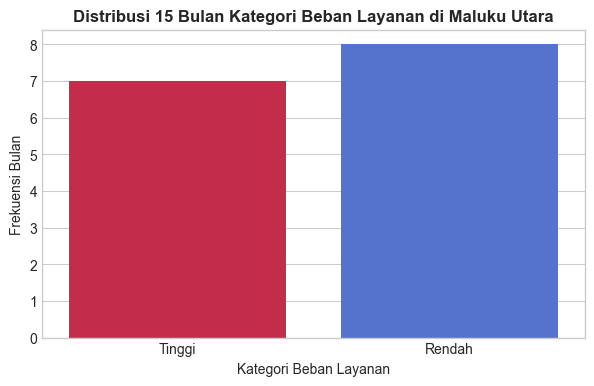

In [11]:
plt.figure(figsize=(7, 4))
sns.countplot(data=dataset_15, x='kategori', hue='kategori', palette={'Tinggi':'crimson', 'Rendah':'royalblue'}, legend=False)
plt.title('Distribusi 15 Bulan Kategori Beban Layanan di Maluku Utara', fontsize=12, fontweight='bold')
plt.xlabel('Kategori Beban Layanan')
plt.ylabel('Frekuensi Bulan')
plt.show()


---
## SOAL NO. 2: PERHITUNGAN MODEL KNN

Pada bagian ini, kita melakukan 2 tahap pengujian manual:
1. Bagian 2A (Validasi Data Uji): Menguji data bulan ke-15 (Maret 2026) menggunakan 14 bulan data latih (Jan 2025 - Feb 2026).
2. Bagian 2B (Pengujian Kasus Data Baru): Menguji data kasus operasional baru (**April 2026**) menggunakan model yang telah dilatih pada seluruh 15 data historis.

### Rumus Jarak Euclidean Multi-Dimensi (8 Variabel):
$$d(X_i, X_{\text{uji}}) = \sqrt{\sum_{k=1}^{8} (X_{i,k} - X_{\text{uji},k})^2}$$


### BAGIAN 2A: VALIDASI MANUAL DATA UJI
- Data Latih (*Training Set*): 14 baris (Januari 2025 s/d Februari 2026).
- Data Uji (*Testing Data*): Baris ke-15 (Maret 2026) dengan vektor:
  $$X_{\text{uji}} = [11, 27, 45, 28, 18, 22, 6, 22]$$


In [12]:
train_data_14 = dataset_15.iloc[:14].copy()
test_data_mar = dataset_15.iloc[14:15].copy()

X_train_14 = train_data_14[fitur_usia].values
y_train_14 = train_data_14['kategori'].values
X_test_mar = test_data_mar[fitur_usia].values[0]

selisih_kuadrat_mar = (X_train_14 - X_test_mar)**2
jumlah_kuadrat_mar = np.sum(selisih_kuadrat_mar, axis=1)
jarak_euclidean_mar = np.sqrt(jumlah_kuadrat_mar)

tabel_jarak_mar = pd.DataFrame({
    'Bulan': train_data_14['bulan'] + ' ' + train_data_14['tahun'].astype(str),
    'Jumlah Kuadrat Selisih': np.round(jumlah_kuadrat_mar, 2),
    'Jarak Euclidean (d)': np.round(jarak_euclidean_mar, 4),
    'Kategori': y_train_14
}).sort_values(by='Jarak Euclidean (d)').reset_index(drop=True)
tabel_jarak_mar['Ranking'] = range(1, len(tabel_jarak_mar) + 1)

print("=== TABEL JARAK MANUAL DARI MARET 2026 KE 14 BULAN HISTORIS ===")
display(tabel_jarak_mar[['Ranking', 'Bulan', 'Jumlah Kuadrat Selisih', 'Jarak Euclidean (d)', 'Kategori']].head(6))

top_3_mar = tabel_jarak_mar.head(3)
voting_mar = top_3_mar['Kategori'].value_counts()
print("\nVoting Suara K=3 (Maret 2026):")
print(voting_mar)
print(f"Prediksi Manual Maret 2026: {voting_mar.idxmax().upper()}")


=== TABEL JARAK MANUAL DARI MARET 2026 KE 14 BULAN HISTORIS ===


,Ranking,Bulan,Jumlah Kuadrat Selisih,Jarak Euclidean (d),Kategori
0,1,Maret 2025,981.0,31.3209,Rendah
1,2,April 2025,1400.0,37.4166,Rendah
2,3,Mei 2025,3789.0,61.5549,Rendah
3,4,November 2025,4212.0,64.8999,Rendah
4,5,Februari 2026,4274.0,65.3758,Rendah
5,6,Agustus 2025,4592.0,67.7643,Rendah



Voting Suara K=3 (Maret 2026):
Kategori
Rendah    3
Name: count, dtype: int64
Prediksi Manual Maret 2026: RENDAH



  Skenario Kasus Baru:
  
  Berdasarkan estimasi pendaftaran M-Paspor awal, data permohonan bulan April 2026 memiliki profil permohonan 8 kelompok usia:
  $$X_{\text{April 2026}} = [18, 25, 50, 40, 55, 60, 30, 15] \quad (\text{Total} = 293\text{ pemohon})$$


In [13]:
# Step 2B.1: Menyiapkan 15 Data Latih dan Vektor Kasus Baru April 2026
X_train_all_15 = dataset_15[fitur_usia].values
y_train_all_15 = dataset_15['kategori'].values

X_baru_april = np.array([18, 25, 50, 40, 55, 60, 30, 15])
print("Vektor Kasus Baru April 2026 (8 Fitur Usia):")
print(dict(zip(fitur_usia, X_baru_april)))
print(f"Total Estimasi Permohonan April 2026: {np.sum(X_baru_april)} orang")

selisih_kuadrat_apr = (X_train_all_15 - X_baru_april)**2
jumlah_kuadrat_apr = np.sum(selisih_kuadrat_apr, axis=1)
jarak_euclidean_apr = np.sqrt(jumlah_kuadrat_apr)

tabel_jarak_april = pd.DataFrame({
    'Bulan': dataset_15['bulan'] + ' ' + dataset_15['tahun'].astype(str),
    'Total Paspor': dataset_15['total'],
    'Jumlah Kuadrat Selisih': np.round(jumlah_kuadrat_apr, 2),
    'Jarak Euclidean (d)': np.round(jarak_euclidean_apr, 4),
    'Kategori': y_train_all_15
}).sort_values(by='Jarak Euclidean (d)').reset_index(drop=True)
tabel_jarak_april['Ranking'] = range(1, len(tabel_jarak_april) + 1)

print("\n=== TABEL PERHITUNGAN JARAK MANUAL DARI KASUS BARU (APRIL 2026) KE 15 DATA LATIH ===")
display(tabel_jarak_april[['Ranking', 'Bulan', 'Total Paspor', 'Jumlah Kuadrat Selisih', 'Jarak Euclidean (d)', 'Kategori']])

top_3_apr = tabel_jarak_april.head(3)
print("\n=== 3 TETANGGA TERDEKAT KASUS BARU (APRIL 2026) ===")
display(top_3_apr[['Ranking', 'Bulan', 'Total Paspor', 'Jarak Euclidean (d)', 'Kategori']])

voting_apr = top_3_apr['Kategori'].value_counts()
print("\nHasil Voting Suara Terbanyak Kasus Baru (April 2026):")
print(voting_apr)
prediksi_manual_apr = voting_apr.idxmax()
print(f"\n>>> KESIMPULAN MANUAL KNN (K=3): Kasus Baru April 2026 -> KATEGORI '{prediksi_manual_apr.upper()}' <<<")


Vektor Kasus Baru April 2026 (8 Fitur Usia):
{'0-10': np.int64(18), '11-20': np.int64(25), '21-30': np.int64(50), '31-40': np.int64(40), '41-50': np.int64(55), '51-60': np.int64(60), '61-70': np.int64(30), 'DIATAS 70': np.int64(15)}
Total Estimasi Permohonan April 2026: 293 orang

=== TABEL PERHITUNGAN JARAK MANUAL DARI KASUS BARU (APRIL 2026) KE 15 DATA LATIH ===


,Ranking,Bulan,Total Paspor,Jumlah Kuadrat Selisih,Jarak Euclidean (d),Kategori
0,1,November 2025,271.0,444.0,21.0713,Rendah
1,2,Agustus 2025,323.0,632.0,25.1396,Rendah
2,3,Mei 2025,244.0,669.0,25.8650,Rendah
3,4,Februari 2026,279.0,694.0,26.3439,Rendah
4,5,April 2025,235.0,728.0,26.9815,Rendah
5,6,Juni 2025,321.0,968.0,31.1127,Rendah
6,7,Juli 2025,365.0,1428.0,37.7889,Tinggi
7,8,Maret 2025,176.0,2047.0,45.2438,Rendah
8,9,Februari 2025,405.0,2740.0,52.3450,Tinggi
9,10,Januari 2025,419.0,2880.0,53.6656,Tinggi



=== 3 TETANGGA TERDEKAT KASUS BARU (APRIL 2026) ===


,Ranking,Bulan,Total Paspor,Jarak Euclidean (d),Kategori
0,1,November 2025,271.0,21.0713,Rendah
1,2,Agustus 2025,323.0,25.1396,Rendah
2,3,Mei 2025,244.0,25.8650,Rendah



Hasil Voting Suara Terbanyak Kasus Baru (April 2026):
Kategori
Rendah    3
Name: count, dtype: int64

>>> KESIMPULAN MANUAL KNN (K=3): Kasus Baru April 2026 -> KATEGORI 'RENDAH' <<<


---
## SOAL NO. 3: PEMBUATAN PROGRAM MACHINE LEARNING DENGAN PYTHON (SCIKIT-LEARN)

Kita mengimplementasikan algoritma KNN Multi-Variabel menggunakan kelas `KNeighborsClassifier` dari pustaka `sklearn`.  
Model dilatih pada 15 data historis dan diuji untuk memprediksi data kasus baru bulan **April 2026**.


In [14]:
X_train_model = dataset_15[fitur_usia]
y_train_model = dataset_15['kategori']

df_april_baru = pd.DataFrame([X_baru_april], columns=fitur_usia)

knn_model = KNeighborsClassifier(n_neighbors=3, metric='euclidean')
knn_model.fit(X_train_model, y_train_model)

prediksi_sklearn_apr = knn_model.predict(df_april_baru)[0]
probabilitas_apr = knn_model.predict_proba(df_april_baru)[0]

print("=== HASIL PREDIKSI PROGRAM PYTHON (SCIKIT-LEARN) PADA KASUS BARU APRIL 2026 ===")
print(f"Input Vektor April 2026              : {X_baru_april.tolist()}")
print(f"Prediksi Kelas Model KNN (K=3)       : {prediksi_sklearn_apr}")
print(f"Probabilitas Kelas {knn_model.classes_} : {probabilitas_apr}")
print(f"Kesesuaian dengan Hitungan Manual    : {prediksi_sklearn_apr == prediksi_manual_apr}")


=== HASIL PREDIKSI PROGRAM PYTHON (SCIKIT-LEARN) PADA KASUS BARU APRIL 2026 ===
Input Vektor April 2026              : [18, 25, 50, 40, 55, 60, 30, 15]
Prediksi Kelas Model KNN (K=3)       : Rendah
Probabilitas Kelas ['Rendah' 'Tinggi'] : [1. 0.]
Kesesuaian dengan Hitungan Manual    : True


C:\Users\acer\AppData\Local\Temp\ipykernel_113396\3935413217.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=tabel_jarak_april, x='Bulan', y='Jarak Euclidean (d)', palette=palette_colors_apr)


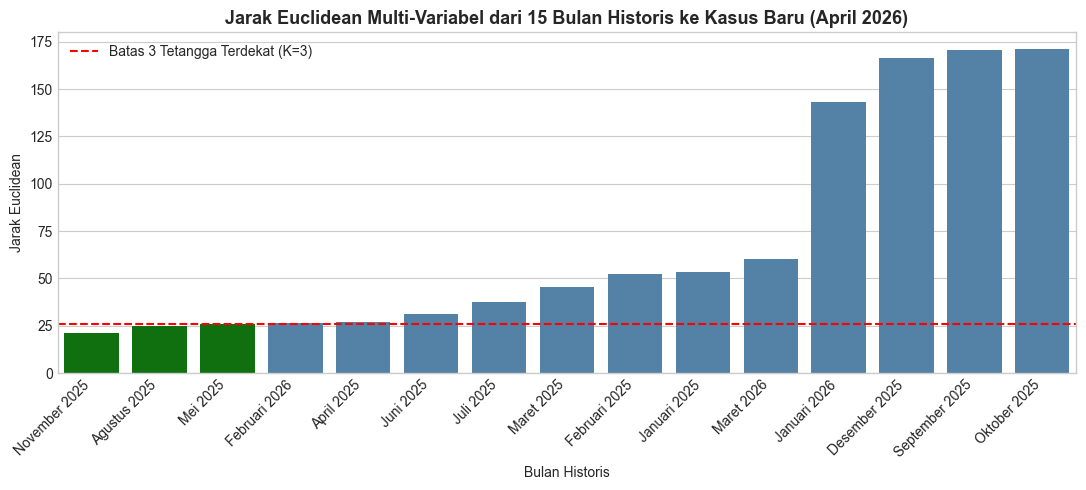

In [15]:
plt.figure(figsize=(11, 5))

palette_colors_apr = ['green' if r <= 3 else 'steelblue' for r in tabel_jarak_april['Ranking']]
sns.barplot(data=tabel_jarak_april, x='Bulan', y='Jarak Euclidean (d)', palette=palette_colors_apr)

plt.title('Jarak Euclidean Multi-Variabel dari 15 Bulan Historis ke Kasus Baru (April 2026)', fontsize=13, fontweight='bold')
plt.xlabel('Bulan Historis')
plt.ylabel('Jarak Euclidean')
plt.xticks(rotation=45, ha='right')
plt.axhline(tabel_jarak_april.loc[2, 'Jarak Euclidean (d)'], color='red', linestyle='--', label='Batas 3 Tetangga Terdekat (K=3)')
plt.legend()
plt.tight_layout()
plt.show()
